# Cell-importance localization and perturbation

Figure 7: cellular maps, localization, and prediction changes after cell removal.

In [ ]:
import warnings
warnings.filterwarnings('ignore', message='IProgress not found.*')
warnings.filterwarnings('ignore', message='The TBB threading layer.*')
from pathlib import Path
import json, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import wilcoxon, pearsonr
from scdecage.tutorials_utils.plotting import DATA_ROOT, setup, output, letter, show_figure
DATA = Path('outputs/model_analyses/cell_importance')
OUT = Path('outputs/figures')
OUT.mkdir(parents=True, exist_ok=True)
BLUE, PALE, GREY, SALMON = '#648DA3', '#C6DEE8', '#B8B8B2', '#CD886E'
setup()
PLOT_CONFIG = {'export_dpi': 800, 'display_width_fraction': 0.45, 'display_width_px': 480,
               'inline_max_pixels': [1100, 1600], 'bootstrap_draws': 2000,
               'cell_budget': 500, 'figure': 'Figure7', 'dataset': 'OneK1K'}
from matplotlib.colors import LinearSegmentedColormap


## Single-model cellular maps

Extract the Zenodo data and set `SCDECAGE_RELEASE_DATA` to its `data` directory.

In [ ]:
import torch
from scipy import sparse
from sklearn.decomposition import TruncatedSVD
from sklearn.neighbors import NearestNeighbors
from umap import UMAP
from scdecage.tutorials_utils.inference import load_analysis_model, load_experiment_model, infer_donor, precision_context
TYPE_NAMES = {
    'naive thymus-derived CD4-positive, alpha-beta T cell': 'Naive CD4 T',
    'central memory CD4-positive, alpha-beta T cell': 'Central-memory CD4 T',
    'effector memory CD8-positive, alpha-beta T cell': 'Memory CD8 T',
    'natural killer cell': 'NK', 'naive B cell': 'Naive B', 'memory B cell': 'Memory B',
    'CD14-positive monocyte': 'CD14+ monocyte'}

@torch.inference_mode()
def cell_weights(model, data):
    rows = []
    for item in data:
        _, _, _, _, result = infer_donor(model, item)
        frame = data.metadata.iloc[item['cell_indices']].copy()
        weights = result['aux']['cellular_importance'].float().cpu().numpy()
        frame['attention_weight'] = weights
        order = np.argsort(weights, kind='stable')
        percentile = np.empty(len(weights), dtype=np.float32)
        percentile[order] = np.linspace(0, 1, len(weights), dtype=np.float32)
        frame['attention_percentile'] = percentile
        rows.append(frame)
    return pd.concat(rows, ignore_index=True)

def transcriptomic_map(data, cells, include_central_memory=True):
    frame = cells.copy()
    frame['cell_type_short'] = frame.cell_type.map(TYPE_NAMES)
    types = list(TYPE_NAMES.values())
    if not include_central_memory:
        types.remove('Central-memory CD4 T')
    frame = frame.loc[frame.cell_type_short.isin(types)].copy().reset_index(drop=True)
    indices = frame.cell_index.to_numpy(np.int64)
    ids = np.asarray(data.gene_ids[indices, :data.max_genes])
    values = np.asarray(data.expression_values[indices, :data.max_genes], dtype=np.float32)
    valid = (ids > 0) & (values > 0)
    matrix = sparse.csr_matrix((values[valid],
        (np.broadcast_to(np.arange(len(frame))[:, None], ids.shape)[valid], ids[valid])),
        shape=(len(frame), int(ids.max()) + 1), dtype=np.float32)
    prevalence = np.asarray((matrix > 0).sum(0)).ravel()
    mean = np.asarray(matrix.mean(0)).ravel()
    variance = np.maximum(np.asarray(matrix.power(2).mean(0)).ravel() - mean**2, 0)
    eligible = np.flatnonzero(prevalence >= max(30, int(.001 * len(frame))))
    genes = eligible[np.argsort(variance[eligible])[-3000:]]
    components = TruncatedSVD(n_components=50, n_iter=7, random_state=random.randrange(2**32)).fit_transform(matrix[:, genes]).astype(np.float32)
    scale = components.std(0, ddof=1)
    components = (components - components.mean(0)) / np.maximum(scale, np.quantile(scale, .25))
    xy = UMAP(n_neighbors=40, min_dist=.14, metric='cosine', n_jobs=1,
              init='random', spread=1., repulsion_strength=.70, set_op_mix_ratio=.95,
              local_connectivity=1., negative_sample_rate=4,
              random_state=random.randrange(2**32)).fit_transform(components)
    xy -= xy.mean(0, keepdims=True)
    _, _, orientation = np.linalg.svd(xy, full_matrices=False)
    xy = xy @ orientation.T
    if xy[np.argmax(np.linalg.norm(xy, axis=1)), 0] < 0:
        xy[:, 0] *= -1
    frame['UMAP1'], frame['UMAP2'] = xy[:, 0], xy[:, 1]
    return frame.loc[frame.cell_type_short.ne('Central-memory CD4 T')].copy()


## Plotting calculations

In [ ]:
from matplotlib.lines import Line2D
from itertools import combinations
from statsmodels.stats.multitest import multipletests
TYPES = ['Naive CD4 T', 'Memory CD8 T', 'NK', 'Naive B', 'Memory B', 'CD14+ monocyte']
COLORS = ['#4E79A7', '#8DBF9A', '#DFA765', '#E15759', '#FF9D9A', '#9C755F']

def draw_umap(ax,frame,panel,compact=False):
    if panel=='A':
        for label,color in sorted(zip(TYPES,COLORS),key=lambda item:(frame.cell_type_short==item[0]).sum(),reverse=True):
            g=frame.loc[frame.cell_type_short.eq(label)]
            ax.scatter(g.UMAP1,g.UMAP2,s=.8,c=color,alpha=.75,linewidths=0,rasterized=True)
        handles=[Line2D([],[],linestyle='',marker='o',markersize=2.6,color=c,label=t) for t,c in zip(TYPES,COLORS)]
        ax.legend(handles=handles,loc='lower left',bbox_to_anchor=(.02,.015),ncol=2,
                  frameon=False,fontsize=6.5 if compact else 9.5,handlelength=.8,handletextpad=.45,
                  labelspacing=.30,borderaxespad=.3)
    else:
        cmap=LinearSegmentedColormap.from_list('importance',['#E8EDF0','#A9CBD8','#E3A071','#9F3044'])
        g=frame.sort_values('attention_percentile',kind='stable')
        sc=ax.scatter(g.UMAP1,g.UMAP2,c=g.attention_percentile,cmap=cmap,s=.8,vmin=0,vmax=1,linewidths=0,rasterized=True)
        compact_width=.075/(ax.get_position().width*ax.figure.get_figwidth())
        cax=ax.inset_axes([.93,.34,compact_width,.50] if compact else [.93,.34,.042,.50]);cb=ax.figure.colorbar(sc,cax=cax)
        cb.ax.yaxis.set_ticks_position('left')
        cb.ax.text(1.,1.10,'Importance\npercentile',fontsize=9 if compact else 12,
                   ha='right',va='bottom',transform=cb.ax.transAxes,linespacing=1.05)
        cb.ax.tick_params(labelsize=7.5 if compact else 10,pad=2)
    x=frame.UMAP1;y=frame.UMAP2;dx=x.max()-x.min();dy=y.max()-y.min()
    ax.set(xlim=(x.min()-.03*dx,x.max()+.03*dx),ylim=(y.min()-.06*dy,y.max()+.06*dy),
           xlabel='UMAP1',ylabel='UMAP2',aspect='equal')
    ax.grid(False)
    ax.tick_params(labelsize=8 if compact else 10)

def localization_p_value(localization, perturbations):
    rows=[]
    def add(panel,condition,comparison,left,right):
        z=pd.concat([left.rename('left'),right.rename('right')],axis=1).dropna()
        assert z.index.is_unique
        a,b=z.left.to_numpy(),z.right.to_numpy()
        if np.all(a==b):stat,p=0.,1.
        else:
            result=wilcoxon(a,b,alternative='two-sided');stat,p=float(result.statistic),float(result.pvalue)
        rows.append({'panel':panel,'condition':condition,'comparison':comparison,'n_donors':len(z),
                     'test_statistic':stat,'p_raw':p,'median_left_minus_right':float(np.median(a-b))})
    loc=localization.set_index('donor_id')
    add('C','Global localization','RAGA vs cell-type-matched random',loc.observed,loc.matched_random)
    strategies=['Highest-importance','Cell-type-matched random','Lowest-importance']
    pairs=list(combinations(strategies,2))
    # Zero removal is identically zero for all strategies and is not a hypothesis.
    for fraction in [5,10,20,30]:
        f=perturbations.loc[perturbations.fraction.eq(fraction)]
        wide=f.pivot(index='donor_id',columns='strategy',values='delta_error')
        for left,right in pairs:add('D',f'{fraction}% cells removed',f'{left} vs {right}',wide[left],wide[right])
    f=perturbations.loc[perturbations.fraction.eq(10)].copy()
    ages=f[['donor_id','age']].drop_duplicates();assert ages.donor_id.is_unique
    cuts=ages.age.quantile([.25,.5,.75]).to_numpy()
    f['quartile']=np.searchsorted(cuts,f.age.to_numpy(),side='right')
    f['shift']=abs(f.prediction-f.baseline_prediction)
    for q in range(4):
        wide=f.loc[f.quartile.eq(q)].pivot(index='donor_id',columns='strategy',values='shift')
        for left,right in pairs:add('E',f'Age Q{q+1}; 10% cells removed',f'{left} vs {right}',wide[left],wide[right])
    assert len(rows)==25
    adjusted=multipletests([row['p_raw'] for row in rows],method='holm')[1]
    for row,p in zip(rows,adjusted):row['p_holm']=float(p)
    return rows[0]['p_holm']

def paired(ax, left, right, labels, ylabel, ptext=True, connect=True, annotation_fontsize=9):
    rng = np.random.default_rng(random.randrange(2 ** 32))
    if connect:
        for a, b in zip(left, right):
            ax.plot([0, 1], [a, b], color=PALE, alpha=0.12, lw=0.45, zorder=1)
    box = ax.boxplot([left, right], positions=[0, 1], widths=0.45, patch_artist=True, showfliers=False, medianprops={'color': '#45515B', 'lw': 1.0})
    for patch, color in zip(box['boxes'], [PALE, BLUE]):
        patch.set_facecolor(color)
        patch.set_alpha(0.8)
    for i, values in enumerate([left, right]):
        ax.scatter(i + rng.normal(0, 0.075, len(values)), values, s=3, alpha=0.2, color=BLUE, edgecolors='none', rasterized=True)
    ax.set_xticks([0, 1], labels)
    ax.set_ylabel(ylabel)
    ax.grid(axis='y')
    ax.set_axisbelow(True)
    if ptext:
        mask = np.isfinite(left) & np.isfinite(right)
        p = wilcoxon(np.asarray(left)[mask], np.asarray(right)[mask]).pvalue if mask.sum() > 4 and (not np.allclose(np.asarray(left)[mask], np.asarray(right)[mask])) else 1.0
        ax.text(0.98, 0.98, f'Paired Wilcoxon P={p:.2g}', ha='right', va='top', transform=ax.transAxes, fontsize=annotation_fontsize, bbox={'facecolor': 'white', 'edgecolor': 'none', 'pad': 2})

def mean_ci(values, random_state=random.randrange(2 ** 32)):
    values = np.asarray(values, float)
    values = values[np.isfinite(values)]
    rng = np.random.default_rng(random_state)
    boot = rng.choice(values, (PLOT_CONFIG['bootstrap_draws'], len(values)), replace=True).mean(1)
    return (values.mean(), *np.quantile(boot, [0.025, 0.975]))

def figure7(root, panels='ABCDE', embedding=None):
    rng = np.random.default_rng()
    directory = OUT / 'figure7'
    if set(panels) & set('CDE'):
        loc = pd.read_csv(root / 'localization.csv', float_precision='round_trip')
        per = pd.read_csv(root / 'cell_removal.csv', float_precision='round_trip')
        names = ['Highest-importance', 'Cell-type-matched random', 'Lowest-importance']
        colors = [SALMON, GREY, BLUE]
        adjusted_p = localization_p_value(loc, per)

    def panel_a(ax):
        draw_umap(ax, embedding, 'A')
        letter(ax, 'A')

    def panel_b(ax):
        draw_umap(ax, embedding, 'B')
        letter(ax, 'B')

    def panel_c(ax):
        paired(ax, loc.observed.to_numpy(), loc.matched_random.to_numpy(), ['RAGA', 'Cell-type-matched\nrandom'], 'kNN localization score', ptext=False, connect=False)
        ax.set_ylim(0, 0.97)
        ax.text(0.03, 0.04, f'Holm-adjusted P = {adjusted_p:.2e}', transform=ax.transAxes, fontsize=10, bbox={'facecolor': 'white', 'edgecolor': '#CCCCCC', 'pad': 1.5})
        letter(ax, 'C')

    def panel_d(ax):
        for strategy, color in zip(names, colors):
            vals = []
            for fraction, g in per[per.strategy.eq(strategy)].groupby('fraction'):
                mu, lo, hi = mean_ci(g.delta_error)
                vals.append((fraction, mu, lo, hi))
            x, mu, lo, hi = np.asarray(vals).T
            ax.plot(x, mu, 'o-', lw=1.5, ms=4, c=color, label=strategy)
            ax.fill_between(x, lo, hi, color=color, alpha=0.18)
        ax.axhline(0, color='#6C747A', lw=0.7)
        ax.set_xlabel('Removed cells (%)')
        ax.set_ylabel('ΔMAE after cell removal')
        ax.grid()
        ax.legend(frameon=False, fontsize=9)
        letter(ax, 'D')

    def panel_e(ax):
        g = per[per.fraction.eq(10)].copy()
        g['shift'] = abs(g.prediction - g.baseline_prediction)
        ages = g[['donor_id', 'age']].drop_duplicates()
        cuts = ages.age.quantile([0.25, 0.5, 0.75]).to_numpy()
        g['q'] = np.searchsorted(cuts, g.age.to_numpy(), side='right')
        for i, (strategy, color) in enumerate(zip(names, colors)):
            vals = [g.loc[g.strategy.eq(strategy) & g.q.eq(q), 'shift'].to_numpy() for q in range(4)]
            positions = np.arange(4) + (i - 1) * 0.24
            b = ax.boxplot(vals, positions=positions, widths=0.2, patch_artist=True, showfliers=False, medianprops={'color': 'black', 'linewidth': 1.1})
            for patch in b['boxes']:
                patch.set_facecolor(color)
                patch.set_alpha(0.7)
            for x, v in zip(positions, vals):
                ax.scatter(x + rng.normal(0, 0.02, len(v)), v, s=3, c=color, alpha=0.13, rasterized=True)
        ax.set_xticks(range(4), ['Q1', 'Q2', 'Q3', 'Q4'])
        ax.set_xlabel('Chronological-age quartile')
        ax.set_ylabel('Absolute change in predicted age')
        ax.grid(axis='y')
        letter(ax, 'E')
        from matplotlib.patches import Patch
        ax.legend(handles=[Patch(facecolor=c, label=n) for n, c in zip(names, colors)], title='10%cells removed', frameon=False, fontsize=9)
    for label, fn, size in [('A', panel_a, (5, 4.4)), ('B', panel_b, (5, 4.4)), ('C', panel_c, (5, 4.4)), ('D', panel_d, (7, 4.8)), ('E', panel_e, (9.5, 5.0))]:
        if label not in panels:
            continue
        fig, ax = plt.subplots(figsize=size)
        fn(ax)
        output(fig, directory, 'Figure7' + label)


## Cell-type map

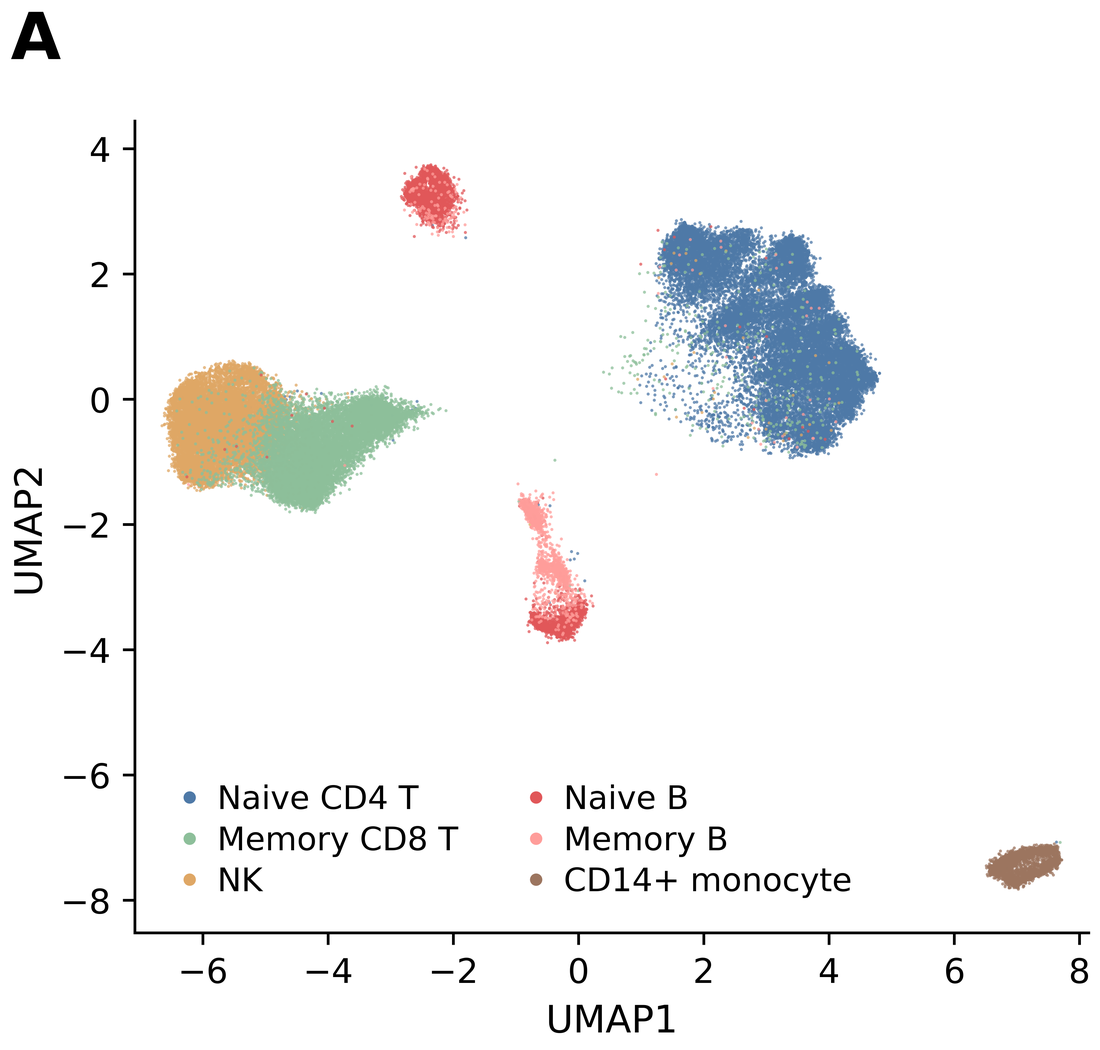

In [3]:
CHECKPOINT = DATA_ROOT / 'OneK1K/model.pth'
model, donor_data = load_analysis_model('OneK1K', checkpoint=CHECKPOINT)
cells = cell_weights(model, donor_data)
embedding = transcriptomic_map(donor_data, cells)
figure7(DATA, panels='AB', embedding=embedding)
show_figure(OUT / 'figure7/Figure7A.png')


## Cellular importance map

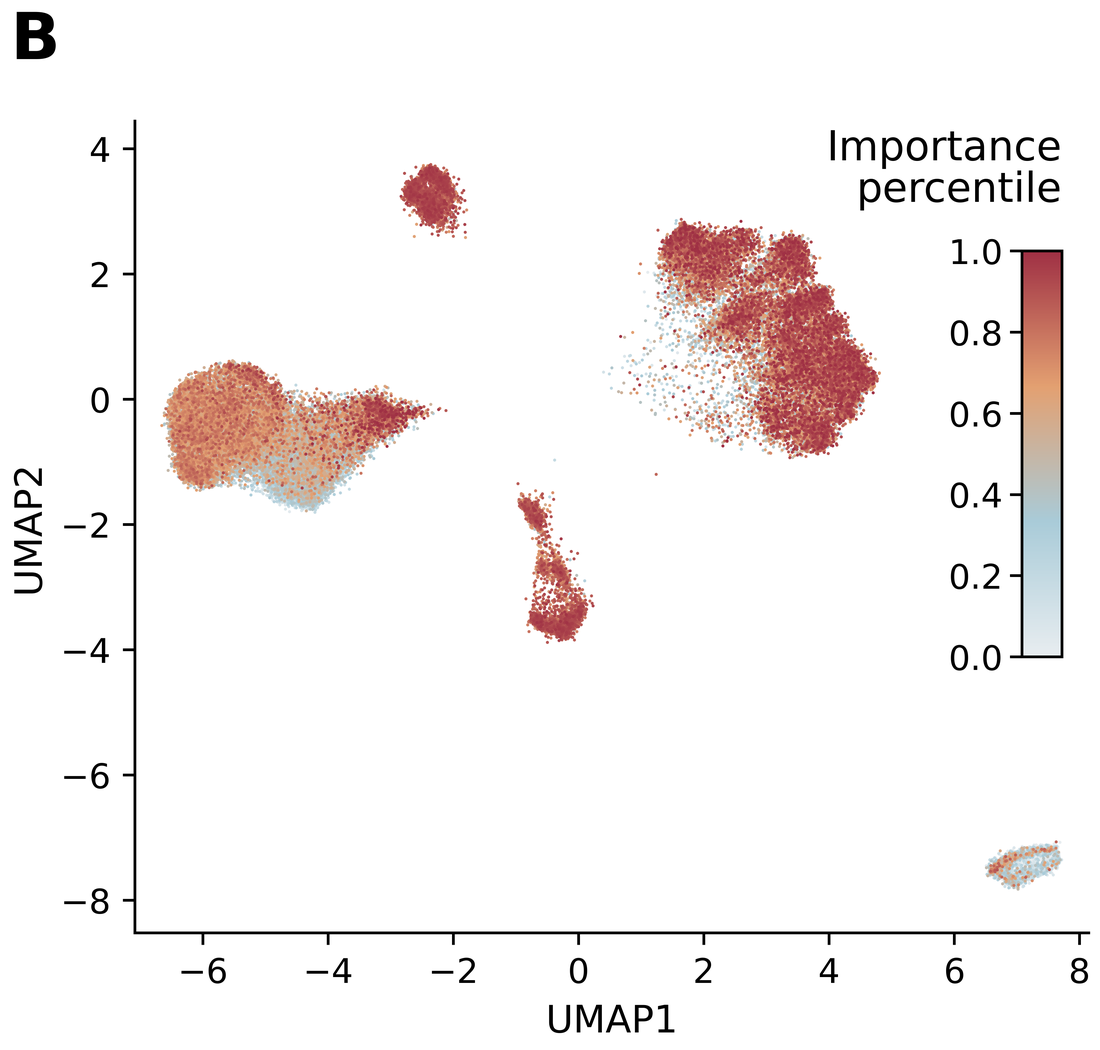

In [4]:
show_figure(OUT / 'figure7/Figure7B.png')


## Multi-model localization and removal

The saved C–E panels combine test partitions. Supply the checkpoint and prepared inputs for each partition to rerun them.

In [ ]:
@torch.inference_mode()
def removal_experiment(model_inputs):
    cells, records = [], []
    rng = np.random.default_rng()
    for specification in model_inputs:
        model, data = load_experiment_model(specification)
        cells.append(cell_weights(model, data))
        for item in data:
            ids, values, pathways, reps, result = infer_donor(model, item)
            full = float(result['pred_age'])
            weights = result['aux']['cellular_importance'].float().cpu().numpy()
            types = item['cell_types']
            order = np.argsort(weights)[::-1]
            for percent in [0, 5, 10, 20, 30]:
                count = min(int(round(len(ids) * percent / 100)), max(len(ids) - 8, 0))
                top = order[:count]
                quotas = {t: int((types[top] == t).sum()) for t in np.unique(types)}
                low = np.concatenate([np.flatnonzero(types == t)[np.argsort(weights[types == t])[:n]]
                                      for t, n in quotas.items() if n]) if count else np.array([], dtype=int)
                actions = [('Highest-importance', top, 0), ('Lowest-importance', low, 0)]
                for repeat in range(5):
                    matched = np.concatenate([rng.choice(np.flatnonzero(types == t), n, replace=False)
                                               for t, n in quotas.items() if n]) if count else np.array([], dtype=int)
                    actions.append(('Cell-type-matched random', matched, repeat))
                for strategy, deleted, repeat in actions:
                    keep = torch.as_tensor(np.setdiff1d(np.arange(len(ids)), deleted), device=reps.device)
                    with precision_context(reps.device):
                        prediction = float(model.aggregator.forward_one(reps[keep], ids[keep], values[keep], pathways[keep])['pred_age'])
                    records.append({'donor_id': item['donor_id'], 'age': float(item['age']),
                                    'fraction': percent, 'strategy': strategy, 'repeat': repeat,
                                    'prediction': prediction, 'baseline_prediction': full})
    cells = pd.concat(cells, ignore_index=True)
    if not cells.cell_index.is_unique:
        raise ValueError('Test-cell assignments must be disjoint across models.')
    cells['importance_percentile'] = cells.groupby('donor_id').attention_weight.rank(method='average', pct=True)
    coordinates = transcriptomic_map(data, cells, include_central_memory=False)
    localization = []
    for donor, group in coordinates.groupby('donor_id', sort=True):
        xy = group[['UMAP1', 'UMAP2']].to_numpy()
        weights = group.importance_percentile.to_numpy()
        if len(group) < 8 or np.std(weights) < 1e-8:
            continue
        neighbors = NearestNeighbors(n_neighbors=min(21, len(group))).fit(xy).kneighbors(xy, return_distance=False)[:, 1:]
        observed = np.corrcoef(weights, weights[neighbors].mean(1))[0, 1]
        null = []
        for _ in range(50):
            shuffled = weights.copy()
            for indices in group.groupby('cell_type_short', observed=True).indices.values():
                shuffled[indices] = rng.permutation(shuffled[indices])
            null.append(np.corrcoef(shuffled, shuffled[neighbors].mean(1))[0, 1])
        localization.append({'donor_id': donor, 'observed': observed, 'matched_random': np.nanmean(null)})
    deletion = pd.DataFrame(records)
    deletion['absolute_error'] = abs(deletion.prediction - deletion.age)
    per = deletion.groupby(['donor_id', 'age', 'fraction', 'strategy'], as_index=False).agg(
        absolute_error=('absolute_error', 'mean'), prediction=('prediction', 'mean'),
        baseline_prediction=('baseline_prediction', 'first'))
    per['delta_error'] = per.absolute_error - abs(per.baseline_prediction - per.age)
    return pd.DataFrame(localization), per


In [ ]:
MODEL_INPUTS = [{'checkpoint': '', 'data_root': '', 'cell_order': ''}]
localization, cell_removal = removal_experiment(MODEL_INPUTS)
DATA.mkdir(parents=True, exist_ok=True)
localization.to_csv(DATA / 'localization.csv', index=False, float_format='%.17g')
cell_removal.to_csv(DATA / 'cell_removal.csv', index=False, float_format='%.17g')


## Localization of cellular importance

In [ ]:
figure7(DATA, panels='CDE')
show_figure(OUT / 'figure7/Figure7C.png')


## Cell-removal response

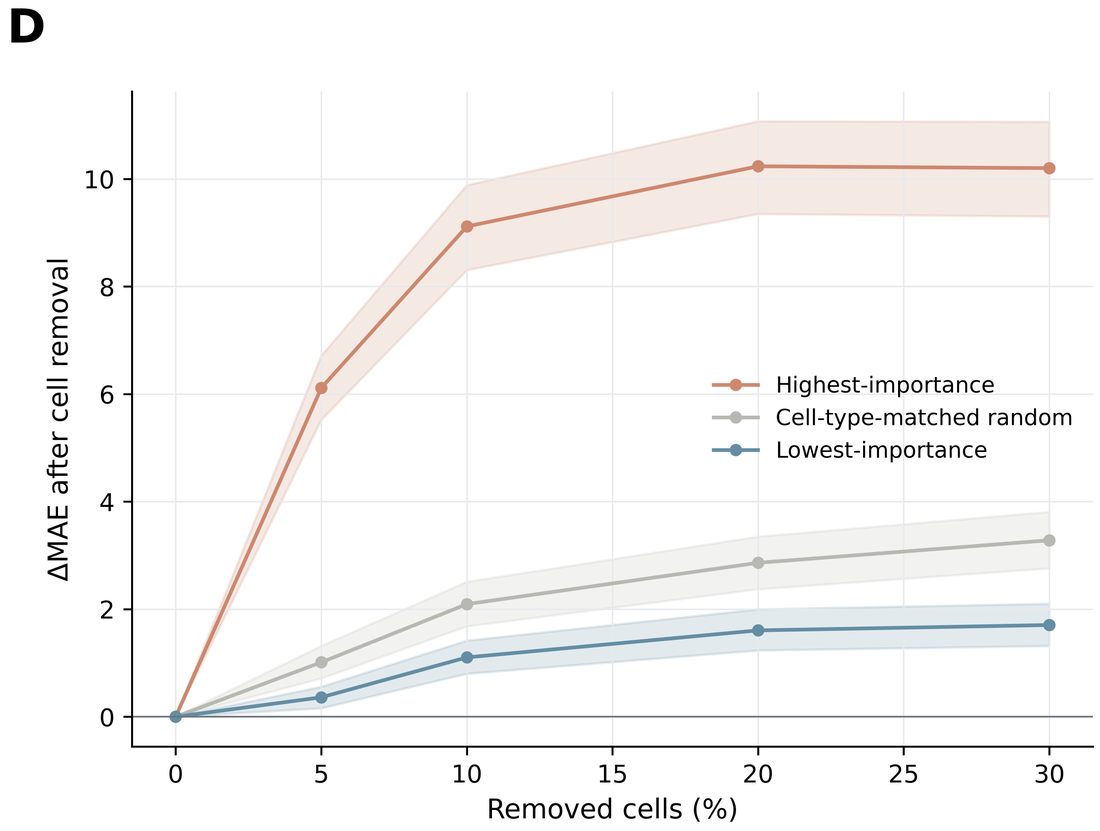

In [6]:
show_figure(OUT / 'figure7/Figure7D.png')


## Age-stratified prediction shifts

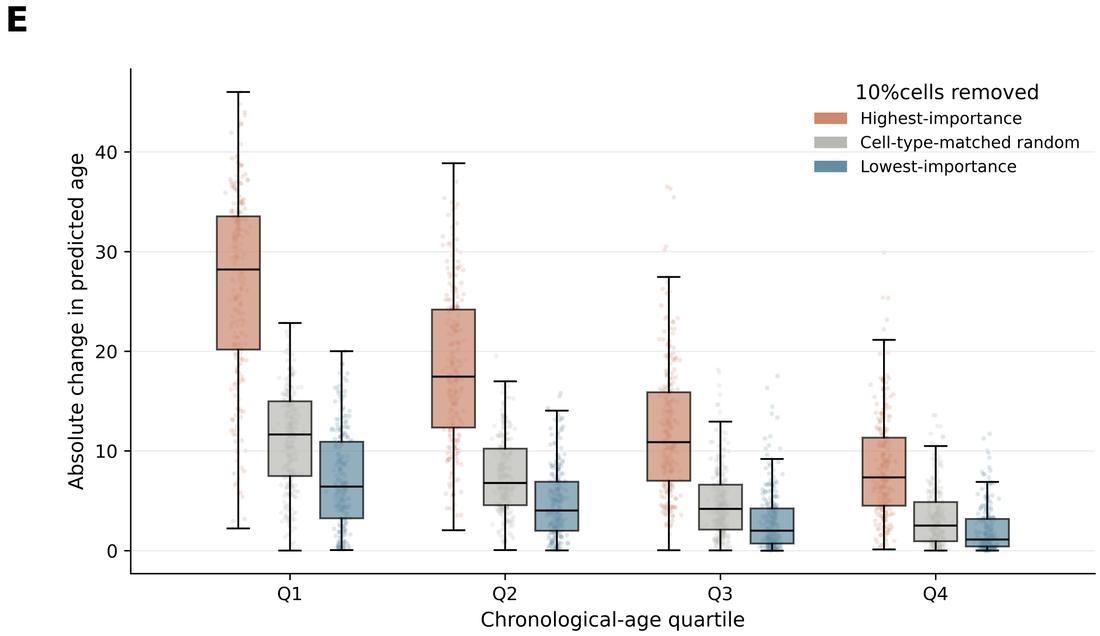

In [7]:
show_figure(OUT / 'figure7/Figure7E.png')
